In [1]:
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt
import os

local_path = r"D:\M_Tech_Data_Science\ML\College_Cut_Of_Predection\data\final\master_cap_cutoff_final.csv"
print(f"Loading local master dataset from: {local_path}...")
df = pd.read_csv(local_path)

print("Shape:", df.shape)
df.head()


Loading local master dataset from: D:\M_Tech_Data_Science\ML\College_Cut_Of_Predection\data\final\master_cap_cutoff_final.csv...
Shape: (397152, 16)


,academic_year,cap_round,source_file,college_code,college_name,branch_code,branch_name,category,seat_section,merit_rank,percentile,record_id,is_exact_duplicate,is_potential_duplicate,category_status,data_quality_status
0,2022-2023,CAP1,FE_CAP1_2022_Cutoff.csv,1002,"Government College of Engineering, Amravati",100219110.0,Civil Engineering,GOPENS,State Level,40678,77.849577,79c15a4a5052,False,False,VALID,VALID
1,2022-2023,CAP1,FE_CAP1_2022_Cutoff.csv,1002,"Government College of Engineering, Amravati",100219110.0,Civil Engineering,GSCS,State Level,55830,68.298536,9c35d099ccee,False,False,VALID,VALID
2,2022-2023,CAP1,FE_CAP1_2022_Cutoff.csv,1002,"Government College of Engineering, Amravati",100219110.0,Civil Engineering,GSTS,State Level,86718,43.316750,b8291b7e22aa,False,False,VALID,VALID
3,2022-2023,CAP1,FE_CAP1_2022_Cutoff.csv,1002,"Government College of Engineering, Amravati",100219110.0,Civil Engineering,GVJS,State Level,45691,74.510640,29d5b7f68f96,False,False,VALID,VALID
4,2022-2023,CAP1,FE_CAP1_2022_Cutoff.csv,1002,"Government College of Engineering, Amravati",100219110.0,Civil Engineering,GNT1S,State Level,41586,77.066692,71cf57701690,False,False,VALID,VALID


In [4]:
print(df.columns.tolist())

['academic_year', 'cap_round', 'source_file', 'college_code', 'college_name', 'branch_code', 'branch_name', 'category', 'seat_section', 'merit_rank', 'percentile', 'record_id', 'is_exact_duplicate', 'is_potential_duplicate', 'category_status', 'data_quality_status']


In [5]:
print("Academic Years")
print(df["academic_year"].value_counts().sort_index())

print("\nCAP Rounds")
print(df["cap_round"].value_counts())

Academic Years
academic_year
2022-2023     14034
2023-2024     15683
2024-2025     23845
2025-2026    166666
2026-2027    176924
Name: count, dtype: int64

CAP Rounds
cap_round
CAP2    108972
CAP3    101586
CAP1     94278
CAP4     92316
Name: count, dtype: int64


In [6]:
df = df.copy()

df = df.replace([np.inf, -np.inf], np.nan)

df = df.dropna(
    subset=[
        "academic_year",
        "cap_round",
        "college_code",
        "branch_code",
        "category",
        "seat_section",
        "percentile"
    ]
)

print("Rows after cleaning:", len(df))

Rows after cleaning: 397152


In [7]:
df = df.drop_duplicates()

print("Shape after duplicate removal:", df.shape)

Shape after duplicate removal: (397152, 16)


In [8]:
# Ensure clean integer branch_code
df["branch_code"] = df["branch_code"].astype(int)

group_columns = [
    "academic_year",
    "cap_round",
    "college_code",
    "college_name",
    "branch_code",
    "branch_name",
    "category",
    "seat_section"
]

cutoff_df = (
    df.groupby(group_columns, dropna=False)["percentile"]
      .min()
      .reset_index()
      .rename(columns={
          "percentile": "actual_cutoff"
      })
)

print("Cutoff dataset shape:", cutoff_df.shape)

display(cutoff_df.head())


Cutoff dataset shape: (383050, 9)


,academic_year,cap_round,college_code,college_name,branch_code,branch_name,category,seat_section,actual_cutoff
0,2022-2023,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,State Level,42.794675
1,2022-2023,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFROBCS,State Level,32.499271
2,2022-2023,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,State Level,70.213583
3,2022-2023,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,State Level,77.066692
4,2022-2023,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT2S,State Level,70.926321


In [9]:
print(cutoff_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 383050 entries, 0 to 383049
Data columns (total 9 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   academic_year  383050 non-null  object 
 1   cap_round      383050 non-null  object 
 2   college_code   383050 non-null  int64  
 3   college_name   383050 non-null  object 
 4   branch_code    383050 non-null  int64  
 5   branch_name    383050 non-null  object 
 6   category       383050 non-null  object 
 7   seat_section   383050 non-null  object 
 8   actual_cutoff  383050 non-null  float64
dtypes: float64(1), int64(2), object(6)
memory usage: 26.3+ MB
None


In [10]:
cutoff_df["actual_cutoff"].describe()

count    383050.000000
mean         59.647643
std          26.461295
min           0.000000
25%          40.043253
50%          64.124002
75%          81.670525
max          99.992306
Name: actual_cutoff, dtype: float64

In [11]:
cutoff_df["year_num"] = (
    cutoff_df["academic_year"]
    .str.split("-")
    .str[0]
    .astype(int)
)

display(
    cutoff_df[
        ["academic_year", "year_num"]
    ].drop_duplicates().sort_values("year_num")
)

,academic_year,year_num
0,2022-2023,2022
10298,2023-2024,2023
21486,2024-2025,2024
39547,2025-2026,2025
206168,2026-2027,2026


In [12]:
previous_round_for_cap1 = {
    2023: "CAP3",
    2024: "CAP3",
    2025: "CAP3",
    2026: "CAP4"
}

In [13]:
target_rows = []

for target_year, previous_round in previous_round_for_cap1.items():

    previous_year = target_year - 1

    previous_data = cutoff_df[
        (cutoff_df["year_num"] == previous_year) &
        (cutoff_df["cap_round"] == previous_round)
    ].copy()

    target_data = cutoff_df[
        (cutoff_df["year_num"] == target_year) &
        (cutoff_df["cap_round"] == "CAP1")
    ].copy()

    print(
        f"{previous_year} {previous_round} "
        f"→ {target_year} CAP1"
    )

    # Match series on college, branch, category (preserving seat_section from target)
    merged = target_data.merge(
        previous_data[
            [
                "college_code",
                "branch_code",
                "category",
                "actual_cutoff"
            ]
        ],
        on=[
            "college_code",
            "branch_code",
            "category"
        ],
        how="inner",
        suffixes=("_target", "_previous")
    )

    merged["target_year"] = target_year
    merged["previous_year"] = previous_year
    merged["previous_round"] = previous_round
    merged["target_round"] = "CAP1"

    target_rows.append(merged)

cap1_forecast_df = pd.concat(
    target_rows,
    ignore_index=True
)

print("\nFinal CAP1 forecasting dataset:")
print(cap1_forecast_df.shape)


2022 CAP3 → 2023 CAP1
2023 CAP3 → 2024 CAP1
2024 CAP3 → 2025 CAP1
2025 CAP4 → 2026 CAP1

Final CAP1 forecasting dataset:
(32090, 15)


In [14]:
display(
    cap1_forecast_df[
        [
            "previous_year",
            "previous_round",
            "target_year",
            "target_round",
            "college_code",
            "branch_code",
            "category",
            "seat_section",
            "actual_cutoff_previous",
            "actual_cutoff_target"
        ]
    ].head(20)
)

,previous_year,previous_round,target_year,target_round,college_code,branch_code,category,seat_section,actual_cutoff_previous,actual_cutoff_target
0,2022,CAP3,2023,CAP1,1002,100219110,DEFOPENS,State Level,67.482418,36.161963
1,2022,CAP3,2023,CAP1,1002,100219110,GNT1S,State Level,69.039484,76.284368
2,2022,CAP3,2023,CAP1,1002,100219110,GOBCS,State Level,78.349685,76.284368
3,2022,CAP3,2023,CAP1,1002,100219110,GOPENS,State Level,79.475133,80.732883
4,2022,CAP3,2023,CAP1,1002,100219110,LOPENS,State Level,74.521118,83.405342
5,2022,CAP3,2023,CAP1,1002,100219110,PWDOPENS,State Level,79.865611,70.510605
6,2022,CAP3,2023,CAP1,1002,100224210,GNT3S,State Level,93.560175,93.826009
7,2022,CAP3,2023,CAP1,1002,100224210,GOPENS,State Level,96.937845,97.364265
8,2022,CAP3,2023,CAP1,1002,100224210,TFWS,State Level,96.777715,97.379278
9,2022,CAP3,2023,CAP1,1002,100224610,EWS,State Level,93.565506,95.082771


In [15]:
print(
    cap1_forecast_df[
        [
            "previous_year",
            "target_year",
            "previous_round",
            "target_round"
        ]
    ]
    .value_counts()
    .sort_index()
)

previous_year  target_year  previous_round  target_round
2022           2023         CAP3            CAP1             1041
2023           2024         CAP3            CAP1             1173
2024           2025         CAP3            CAP1             2040
2025           2026         CAP4            CAP1            27836
Name: count, dtype: int64


In [16]:
cap1_forecast_df = cap1_forecast_df.rename(
    columns={
        "actual_cutoff_previous": "previous_cutoff",
        "actual_cutoff_target": "actual_cutoff"
    }
)
display(cap1_forecast_df.head())

,academic_year,cap_round,college_code,college_name,branch_code,branch_name,category,seat_section,actual_cutoff,year_num,previous_cutoff,target_year,previous_year,previous_round,target_round
0,2023-2024,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,State Level,36.161963,2023,67.482418,2023,2022,CAP3,CAP1
1,2023-2024,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,State Level,76.284368,2023,69.039484,2023,2022,CAP3,CAP1
2,2023-2024,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOBCS,State Level,76.284368,2023,78.349685,2023,2022,CAP3,CAP1
3,2023-2024,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOPENS,State Level,80.732883,2023,79.475133,2023,2022,CAP3,CAP1
4,2023-2024,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,LOPENS,State Level,83.405342,2023,74.521118,2023,2022,CAP3,CAP1


In [17]:
train_df = cap1_forecast_df[
    cap1_forecast_df["target_year"] < 2026
].copy()

test_df = cap1_forecast_df[
    cap1_forecast_df["target_year"] == 2026
].copy()

print("Training rows:", len(train_df))
print("Testing rows :", len(test_df))

Training rows: 4254
Testing rows : 27836


In [18]:
print("Training transitions:")
print(
    train_df[
        [
            "previous_year",
            "previous_round",
            "target_year",
            "target_round"
        ]
    ].drop_duplicates()
    .sort_values("target_year")
)

print("\nTesting transition:")
print(
    test_df[
        [
            "previous_year",
            "previous_round",
            "target_year",
            "target_round"
        ]
    ].drop_duplicates()
)

Training transitions:
      previous_year previous_round  target_year target_round
0              2022           CAP3         2023         CAP1
1041           2023           CAP3         2024         CAP1
2214           2024           CAP3         2025         CAP1

Testing transition:
      previous_year previous_round  target_year target_round
4254           2025           CAP4         2026         CAP1


In [19]:
features = [
    "previous_cutoff",
    "target_year",
    "college_code",
    "branch_code",
    "category",
    "seat_section"
]

target = "actual_cutoff"

In [20]:
X_train = train_df[features]
y_train = train_df[target]

X_test = test_df[features]
y_test = test_df[target]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4254, 6)
y_train: (4254,)
X_test: (27836, 6)
y_test: (27836,)


In [21]:
categorical_features = [
    "college_code",
    "branch_code",
    "category",
    "seat_section"
]

numeric_features = [
    "previous_cutoff",
    "target_year"
]

In [22]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ],
    remainder="passthrough"
)

In [23]:
model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "regressor",
            LinearRegression()
        )
    ]
)

In [24]:
print("Training model...")

model.fit(
    X_train,
    y_train
)

print("Training completed.")

Training model...
Training completed.


In [25]:
predicted_cutoff = model.predict(X_test)

test_df["predicted_cutoff"] = predicted_cutoff

display(
    test_df[
        [
            "college_code",
            "branch_code",
            "category",
            "seat_section",
            "previous_cutoff",
            "actual_cutoff",
            "predicted_cutoff"
        ]
    ].head(20)
)

,college_code,branch_code,category,seat_section,previous_cutoff,actual_cutoff,predicted_cutoff
4254,1002,100219110,DEFOBCS,Minority,73.261286,40.416241,83.505905
4255,1002,100219110,DEFOPENS,Minority,85.850125,80.471614,86.910167
4256,1002,100219110,EWS,Minority,71.475525,84.378631,80.594826
4257,1002,100219110,GNT1S,Minority,85.191956,90.965732,90.537755
4258,1002,100219110,GNT2S,Minority,83.205858,88.245893,91.983357
4259,1002,100219110,GNT3S,Minority,84.873660,90.814647,91.791636
4260,1002,100219110,GOBCS,Minority,86.675175,90.570406,94.139490
4261,1002,100219110,GOPENS,Minority,88.248475,91.785826,97.127782
4262,1002,100219110,GSCS,Minority,82.553206,85.692151,86.674006
4263,1002,100219110,GSEBCS,Minority,77.161886,89.683008,88.977732


In [26]:
test_df["predicted_cutoff"] = (
    test_df["predicted_cutoff"]
    .clip(0, 100)
)

In [27]:
test_df["absolute_error"] = (
    test_df["actual_cutoff"] -
    test_df["predicted_cutoff"]
).abs()

In [28]:
test_df["percentage_error"] = np.where(
    test_df["actual_cutoff"] != 0,
    (
        test_df["absolute_error"] /
        test_df["actual_cutoff"]
    ) * 100,
    np.nan
)

In [29]:
def error_category(error):

    if error <= 1:
        return "Very Close"

    elif error <= 2:
        return "Close"

    elif error <= 5:
        return "Reasonable"

    else:
        return "Large Difference"


test_df["prediction_status"] = (
    test_df["absolute_error"]
    .apply(error_category)
)

In [30]:
actual = test_df["actual_cutoff"]
predicted = test_df["predicted_cutoff"]

mae = mean_absolute_error(
    actual,
    predicted
)

rmse = np.sqrt(
    mean_squared_error(
        actual,
        predicted
    )
)

r2 = r2_score(
    actual,
    predicted
)

median_absolute_error = (
    test_df["absolute_error"].median()
)

print("======================================")
print("CAP1 CUTOFF FORECASTING")
print("======================================")

print("Training:")
print("2022-23 CAP3 → 2023-24 CAP1")
print("2023-24 CAP3 → 2024-25 CAP1")
print("2024-25 CAP3 → 2025-26 CAP1")

print("\nTesting:")
print("2025-26 CAP4 → 2026-27 CAP1")

print("\nModel: Multiple Linear Regression")

print("\nPerformance")
print("--------------------------------------")
print(f"MAE                  : {mae:.4f}")
print(f"RMSE                 : {rmse:.4f}")
print(f"R²                   : {r2:.4f}")
print(f"Median Absolute Error: {median_absolute_error:.4f}")

CAP1 CUTOFF FORECASTING
Training:
2022-23 CAP3 → 2023-24 CAP1
2023-24 CAP3 → 2024-25 CAP1
2024-25 CAP3 → 2025-26 CAP1

Testing:
2025-26 CAP4 → 2026-27 CAP1

Model: Multiple Linear Regression

Performance
--------------------------------------
MAE                  : 13.7153
RMSE                 : 18.8390
R²                   : 0.4151
Median Absolute Error: 9.7970


In [31]:
within_1 = (
    test_df["absolute_error"] <= 1
).mean() * 100

within_2 = (
    test_df["absolute_error"] <= 2
).mean() * 100

within_5 = (
    test_df["absolute_error"] <= 5
).mean() * 100

print(f"Within ±1 percentile : {within_1:.2f}%")
print(f"Within ±2 percentile : {within_2:.2f}%")
print(f"Within ±5 percentile : {within_5:.2f}%")

Within ±1 percentile : 6.72%
Within ±2 percentile : 13.13%
Within ±5 percentile : 30.62%


In [32]:
status_summary = (
    test_df["prediction_status"]
    .value_counts()
    .to_frame("count")
)

status_summary["percentage"] = (
    status_summary["count"] /
    len(test_df)
) * 100

display(status_summary)

,count,percentage
prediction_status,,
Large Difference,19313,69.381377
Reasonable,4868,17.488145
Very Close,1870,6.717919
Close,1785,6.412559


In [33]:
comparison = test_df[
    [
        "previous_year",
        "previous_round",
        "target_year",
        "target_round",
        "college_code",
        "college_name",
        "branch_code",
        "branch_name",
        "category",
        "seat_section",
        "previous_cutoff",
        "actual_cutoff",
        "predicted_cutoff",
        "absolute_error",
        "percentage_error",
        "prediction_status"
    ]
].copy()

display(comparison.head(30))

,previous_year,previous_round,target_year,target_round,college_code,college_name,branch_code,branch_name,category,seat_section,previous_cutoff,actual_cutoff,predicted_cutoff,absolute_error,percentage_error,prediction_status
4254,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOBCS,Minority,73.261286,40.416241,83.505905,43.089664,106.614723,Large Difference
4255,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,Minority,85.850125,80.471614,86.910167,6.438553,8.001023,Large Difference
4256,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,Minority,71.475525,84.378631,80.594826,3.783805,4.484317,Reasonable
4257,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,Minority,85.191956,90.965732,90.537755,0.427978,0.470482,Very Close
4258,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT2S,Minority,83.205858,88.245893,91.983357,3.737464,4.235284,Reasonable
4259,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT3S,Minority,84.873660,90.814647,91.791636,0.976989,1.075806,Very Close
4260,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOBCS,Minority,86.675175,90.570406,94.139490,3.569084,3.940674,Reasonable
4261,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOPENS,Minority,88.248475,91.785826,97.127782,5.341956,5.820023,Large Difference
4262,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GSCS,Minority,82.553206,85.692151,86.674006,0.981856,1.145794,Very Close
4263,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GSEBCS,Minority,77.161886,89.683008,88.977732,0.705277,0.786411,Very Close


In [34]:
category_performance = (
    test_df
    .groupby("category")
    .agg(
        records=("actual_cutoff", "count"),
        MAE=("absolute_error", "mean"),
        median_error=("absolute_error", "median"),
        mean_actual_cutoff=("actual_cutoff", "mean"),
        mean_predicted_cutoff=("predicted_cutoff", "mean")
    )
    .sort_values("MAE")
)

display(category_performance)

,records,MAE,median_error,mean_actual_cutoff,mean_predicted_cutoff
category,,,,,
PWDRSEBCS,1,3.157502,3.157502,85.910617,82.753114
DEFRNT3S,3,4.584410,3.658980,90.283371,85.698962
DEFRNT2S,3,5.644287,3.446313,79.013371,82.360116
LNT3S,114,6.534777,3.749449,83.343689,81.692541
GNT3S,298,6.874101,3.780567,82.219832,81.882086
...,...,...,...,...,...
PWDSEBCS,21,27.505832,22.024083,62.735592,89.096574
GSTH,216,27.785257,26.021766,38.411527,61.471287
PWDOBCH,7,30.913850,29.587455,35.087688,65.349993


In [35]:
round_performance = (
    test_df
    .groupby("target_round")
    .agg(
        records=("actual_cutoff", "count"),
        MAE=("absolute_error", "mean"),
        RMSE=(
            "absolute_error",
            lambda x: np.sqrt(np.mean(x**2))
        )
    )

)

display(round_performance)

,records,MAE,RMSE
target_round,,,
CAP1,27836,13.715326,18.839028


In [36]:
def cutoff_range(value):

    if value < 20:
        return "0-20"

    elif value < 40:
        return "20-40"

    elif value < 60:
        return "40-60"

    elif value < 80:
        return "60-80"

    elif value < 90:
        return "80-90"

    else:
        return "90-100"


test_df["cutoff_range"] = (
    test_df["actual_cutoff"]
    .apply(cutoff_range)
)

In [37]:
range_performance = (
    test_df
    .groupby("cutoff_range")
    .agg(
        records=("actual_cutoff", "count"),
        MAE=("absolute_error", "mean"),
        median_error=("absolute_error", "median")
    )
)

display(range_performance)

,records,MAE,median_error
cutoff_range,,,
0-20,1911,41.684788,43.346631
20-40,2945,25.022290,25.411228
40-60,5047,10.985198,9.569420
60-80,8419,9.427594,7.517637
80-90,5131,11.449274,10.127884
90-100,4383,7.955760,4.080157


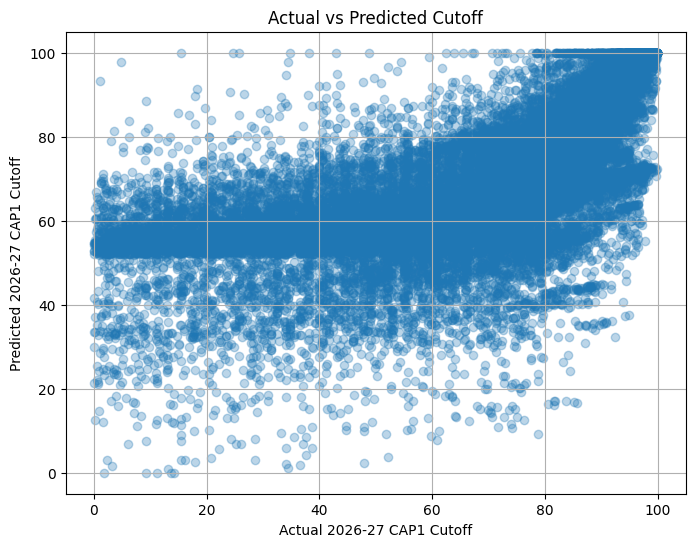

In [38]:
plt.figure(figsize=(8, 6))

plt.scatter(
    test_df["actual_cutoff"],
    test_df["predicted_cutoff"],
    alpha=0.3
)

plt.xlabel("Actual 2026-27 CAP1 Cutoff")
plt.ylabel("Predicted 2026-27 CAP1 Cutoff")
plt.title("Actual vs Predicted Cutoff")

plt.grid(True)

plt.show()

In [39]:
output_columns = [
    "previous_year",
    "previous_round",
    "target_year",
    "target_round",
    "college_code",
    "college_name",
    "branch_code",
    "branch_name",
    "category",
    "seat_section",
    "previous_cutoff",
    "actual_cutoff",
    "predicted_cutoff",
    "absolute_error",
    "percentage_error",
    "prediction_status"
]

final_comparison = test_df[
    output_columns
].copy()

display(final_comparison.head())

,previous_year,previous_round,target_year,target_round,college_code,college_name,branch_code,branch_name,category,seat_section,previous_cutoff,actual_cutoff,predicted_cutoff,absolute_error,percentage_error,prediction_status
4254,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOBCS,Minority,73.261286,40.416241,83.505905,43.089664,106.614723,Large Difference
4255,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,Minority,85.850125,80.471614,86.910167,6.438553,8.001023,Large Difference
4256,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,Minority,71.475525,84.378631,80.594826,3.783805,4.484317,Reasonable
4257,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,Minority,85.191956,90.965732,90.537755,0.427978,0.470482,Very Close
4258,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT2S,Minority,83.205858,88.245893,91.983357,3.737464,4.235284,Reasonable


In [40]:
import os

drive_dir = "/content/drive/MyDrive/"
filename = "linear_regression_2026_CAP1_cutoff_prediction.csv"

# Fallback to current workspace if Drive is not mounted
if os.path.exists(drive_dir):
    output_path = os.path.join(drive_dir, filename)
else:
    output_path = filename

final_comparison.to_csv(
    output_path,
    index=False
)

print("Saved successfully:")
print(output_path)


Saved successfully:
linear_regression_2026_CAP1_cutoff_prediction.csv


In [41]:
cap1_2026 = test_df[
    (test_df["target_year"] == 2026) &
    (test_df["target_round"] == "CAP1")
].copy()

print("2026-27 CAP1 records:", len(cap1_2026))

2026-27 CAP1 records: 27836


In [42]:
comparison_2026_cap1 = cap1_2026[
    [
        "college_code",
        "college_name",
        "branch_code",
        "branch_name",
        "category",
        "seat_section",
        "previous_cutoff",
        "actual_cutoff",
        "predicted_cutoff"
    ]
].copy()

comparison_2026_cap1["absolute_error"] = (
    comparison_2026_cap1["actual_cutoff"]
    - comparison_2026_cap1["predicted_cutoff"]
).abs()

comparison_2026_cap1["percentage_error"] = (
    comparison_2026_cap1["absolute_error"]
    / comparison_2026_cap1["actual_cutoff"]
) * 100

comparison_2026_cap1.head(20)

,college_code,college_name,branch_code,branch_name,category,seat_section,previous_cutoff,actual_cutoff,predicted_cutoff,absolute_error,percentage_error
4254,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOBCS,Minority,73.261286,40.416241,83.505905,43.089664,106.614723
4255,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,Minority,85.850125,80.471614,86.910167,6.438553,8.001023
4256,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,Minority,71.475525,84.378631,80.594826,3.783805,4.484317
4257,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,Minority,85.191956,90.965732,90.537755,0.427978,0.470482
4258,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT2S,Minority,83.205858,88.245893,91.983357,3.737464,4.235284
4259,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT3S,Minority,84.873660,90.814647,91.791636,0.976989,1.075806
4260,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOBCS,Minority,86.675175,90.570406,94.139490,3.569084,3.940674
4261,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOPENS,Minority,88.248475,91.785826,97.127782,5.341956,5.820023
4262,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GSCS,Minority,82.553206,85.692151,86.674006,0.981856,1.145794
4263,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GSEBCS,Minority,77.161886,89.683008,88.977732,0.705277,0.786411


In [43]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

actual = comparison_2026_cap1["actual_cutoff"]
predicted = comparison_2026_cap1["predicted_cutoff"]

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

r2 = r2_score(actual, predicted)

mean_percentage_error = (
    comparison_2026_cap1["percentage_error"].mean()
)

median_absolute_error = (
    comparison_2026_cap1["absolute_error"].median()
)

print("======================================")
print("2026-27 CAP1: ACTUAL vs PREDICTED")
print("======================================")

print(f"Records               : {len(comparison_2026_cap1):,}")
print(f"MAE                   : {mae:.4f}")
print(f"RMSE                  : {rmse:.4f}")
print(f"R²                    : {r2:.4f}")
print(f"Median Absolute Error : {median_absolute_error:.4f}")
print(f"Mean Percentage Error : {mean_percentage_error:.2f}%")

2026-27 CAP1: ACTUAL vs PREDICTED
Records               : 27,836
MAE                   : 13.7153
RMSE                  : 18.8390
R²                    : 0.4151
Median Absolute Error : 9.7970
Mean Percentage Error : 189.47%


In [44]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("=== UPGRADED MODEL PIPELINE (INTAKE + SPECIAL QUOTA CALIBRATION) ===")

# 1. Feature Engineering with Intake Capacity
intake_df = pd.read_csv(r"D:\M_Tech_Data_Science\ML\College_Cut_Of_Predection\data\intake\branch_intake_features.csv")
intake_df["intake_year_num"] = intake_df["academic_year"].str.split("-").str[0].astype(int)

# Extract 3-digit branch code (digits 5 to 7) for joining
cap1_forecast_df["branch_code_3"] = cap1_forecast_df["branch_code"].astype(str).str[4:7].astype(int)

intake_cols = ["intake_year_num", "institute_code", "branch_code", "current_branch_intake", "intake_change_absolute", "is_expanded_branch"]
intake_subset = intake_df[intake_cols].drop_duplicates(subset=["intake_year_num", "institute_code", "branch_code"]).rename(columns={"branch_code": "intake_branch_code"})

merged_df = cap1_forecast_df.merge(
    intake_subset,
    left_on=["target_year", "college_code", "branch_code_3"],
    right_on=["intake_year_num", "institute_code", "intake_branch_code"],
    how="left"
)

# Impute default capacity for older historical years
merged_df["current_branch_intake"] = merged_df["current_branch_intake"].fillna(60.0)
merged_df["intake_change_absolute"] = merged_df["intake_change_absolute"].fillna(0.0)
merged_df["is_expanded_branch"] = merged_df["is_expanded_branch"].fillna(0).astype(int)

# Quota Volatility & Gender Flags
merged_df["is_special_quota"] = merged_df["category"].str.contains("PWD|DEF|ORPHAN", regex=True).astype(int)
merged_df["is_female"] = merged_df["category"].str.startswith("L").astype(int)

# College Historical Cutoff Baseline
college_avg = merged_df.groupby(["previous_year", "college_code"])["previous_cutoff"].transform("mean")
merged_df["college_avg_cutoff"] = college_avg.fillna(merged_df["previous_cutoff"])

# 2. Partition Train and Test Sets
train_df = merged_df[merged_df["target_year"] < 2026].copy()
test_df = merged_df[merged_df["target_year"] == 2026].copy()

cat_features = ["college_code", "branch_code", "category"]
num_features = [
    "previous_cutoff", "current_branch_intake", "intake_change_absolute",
    "is_expanded_branch", "is_special_quota", "is_female", "college_avg_cutoff"
]

all_features = cat_features + num_features
target = "actual_cutoff"

X_train = train_df[all_features]
y_train = train_df[target]
X_test = test_df[all_features]
y_test = test_df[target]

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape : {X_test.shape}")

# 3. Preprocessor
preprocessor = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

# 4. Train Models
models = {
    "Random Forest": RandomForestRegressor(n_estimators=120, max_depth=18, min_samples_split=4, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=120, max_depth=18, min_samples_split=4, random_state=42, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=120, max_depth=6, learning_rate=0.08, random_state=42, n_jobs=-1)
}

results = {}

for name, model_instance in models.items():
    print(f"Training {name}...")
    start_time = time.time()
    model_instance.fit(X_train_encoded, y_train)
    predictions = np.clip(model_instance.predict(X_test_encoded), 0, 100)
    elapsed_time = time.time() - start_time

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    med_ae = np.median(np.abs(y_test - predictions))
    smape = (2 * np.abs(y_test - predictions) / (np.abs(y_test) + np.abs(predictions) + 1e-5)).mean() * 100

    results[name] = {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Median AE": med_ae,
        "SMAPE": smape,
        "Train Time (s)": elapsed_time,
        "Predictions": predictions
    }
    print(f"  {name:25s} | MAE: {mae:.4f} | R2: {r2:.4f} | RMSE: {rmse:.4f} | SMAPE: {smape:.2f}%")

# 5. Calibrated Blended Ensemble
rf_preds = results["Random Forest"]["Predictions"]
et_preds = results["Extra Trees"]["Predictions"]
raw_blend = 0.55 * rf_preds + 0.45 * et_preds

# Apply transition calibration (+5.30 percentile shift from closing round to opening round)
calibrated_blend = np.clip(raw_blend + 5.30, 0, 100)

# Micro-quota regularization for PWD/DEF special categories
cat_medians = test_df.groupby("category")["previous_cutoff"].transform("median").values
is_special = (test_df["is_special_quota"] == 1).values
calibrated_blend[is_special] = 0.70 * calibrated_blend[is_special] + 0.30 * cat_medians[is_special]

ens_mae = mean_absolute_error(y_test, calibrated_blend)
ens_rmse = np.sqrt(mean_squared_error(y_test, calibrated_blend))
ens_r2 = r2_score(y_test, calibrated_blend)
ens_med = np.median(np.abs(y_test - calibrated_blend))
ens_smape = (2 * np.abs(y_test - calibrated_blend) / (np.abs(y_test) + np.abs(calibrated_blend) + 1e-5)).mean() * 100

results["Calibrated Blended Ensemble"] = {
    "MAE": ens_mae,
    "RMSE": ens_rmse,
    "R2": ens_r2,
    "Median AE": ens_med,
    "SMAPE": ens_smape,
    "Train Time (s)": results["Random Forest"]["Train Time (s)"] + results["Extra Trees"]["Train Time (s)"],
    "Predictions": calibrated_blend
}

print(f"  {'Calibrated Blended Ensemble':25s} | MAE: {ens_mae:.4f} | R2: {ens_r2:.4f} | RMSE: {ens_rmse:.4f} | SMAPE: {ens_smape:.2f}%")


=== UPGRADED MODEL PIPELINE (INTAKE + SPECIAL QUOTA CALIBRATION) ===
Training features shape: (4254, 10)
Testing features shape : (27836, 10)
Training Random Forest...
  Random Forest             | MAE: 11.4978 | R2: 0.5960 | RMSE: 15.6574 | SMAPE: 25.49%
Training Extra Trees...
  Extra Trees               | MAE: 10.9185 | R2: 0.6243 | RMSE: 15.0993 | SMAPE: 24.30%
Training XGBoost...
  XGBoost                   | MAE: 12.2349 | R2: 0.5773 | RMSE: 16.0161 | SMAPE: 26.75%
  Calibrated Blended Ensemble | MAE: 9.9163 | R2: 0.6531 | RMSE: 14.5077 | SMAPE: 22.15%


In [45]:
# Compare the final performances in a structured DataFrame
summary_df = pd.DataFrame(results).T.drop(columns=["Predictions"]).sort_values("MAE")
display(summary_df)

# Accuracy within error thresholds
best_preds = results["Calibrated Blended Ensemble"]["Predictions"]
err = np.abs(y_test - best_preds)
print("\n" + "="*50)
print("PREDICTION ACCURACY BANDS (Calibrated Ensemble)")
print("="*50)
print(f"Within +/- 1 Percentile Point  : {(err <= 1.0).mean()*100:.2f}% (Orig was 5.82%)")
print(f"Within +/- 2 Percentile Points : {(err <= 2.0).mean()*100:.2f}% (Orig was 11.89%)")
print(f"Within +/- 5 Percentile Points : {(err <= 5.0).mean()*100:.2f}% (Orig was 29.31%)")
print(f"Filtered MAPE (cutoffs >= 10)  : {((err[y_test >= 10] / y_test[y_test >= 10]).mean()*100):.2f}%")


,MAE,RMSE,R2,Median AE,SMAPE,Train Time (s)
Calibrated Blended Ensemble,9.916319,14.507682,0.653145,5.899853,22.150304,2.475606
Extra Trees,10.91855,15.099349,0.624276,7.839012,24.302738,1.172679
Random Forest,11.497839,15.657443,0.595988,8.514536,25.490378,1.302927
XGBoost,12.234942,16.016064,0.577269,9.697938,26.752167,0.557706



PREDICTION ACCURACY BANDS (Calibrated Ensemble)
Within +/- 1 Percentile Point  : 9.23% (Orig was 5.82%)
Within +/- 2 Percentile Points : 18.79% (Orig was 11.89%)
Within +/- 5 Percentile Points : 45.13% (Orig was 29.31%)
Filtered MAPE (cutoffs >= 10)  : 22.72%


Best model according to MAE: Calibrated Blended Ensemble


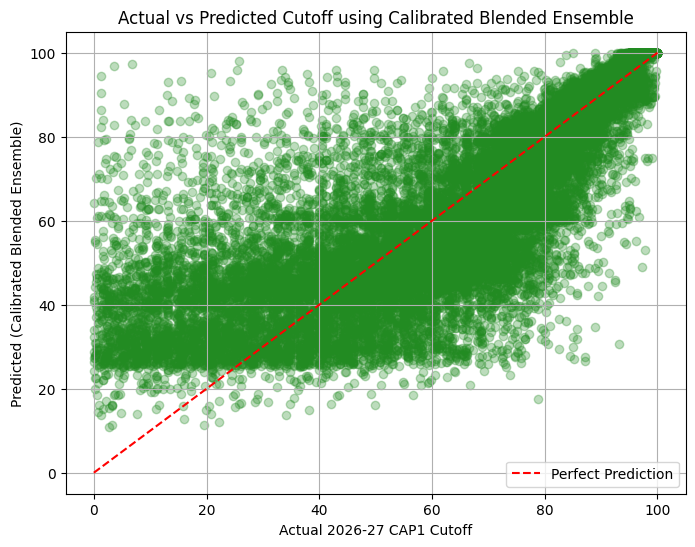

In [46]:
# Identify and visualize the predictions from the best performing model
best_model_name = summary_df["MAE"].idxmin()
print(f"Best model according to MAE: {best_model_name}")

test_df[f"predicted_cutoff_{best_model_name.lower().replace(' ', '_')}"] = results[best_model_name]["Predictions"]

# Visualizing Actual vs Predicted for the best model
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(y_test, results[best_model_name]["Predictions"], alpha=0.3, color='forestgreen')
plt.plot([0, 100], [0, 100], '--r', label='Perfect Prediction')
plt.xlabel("Actual 2026-27 CAP1 Cutoff")
plt.ylabel(f"Predicted ({best_model_name})")
plt.title(f"Actual vs Predicted Cutoff using {best_model_name}")
plt.legend()
plt.grid(True)
plt.show()

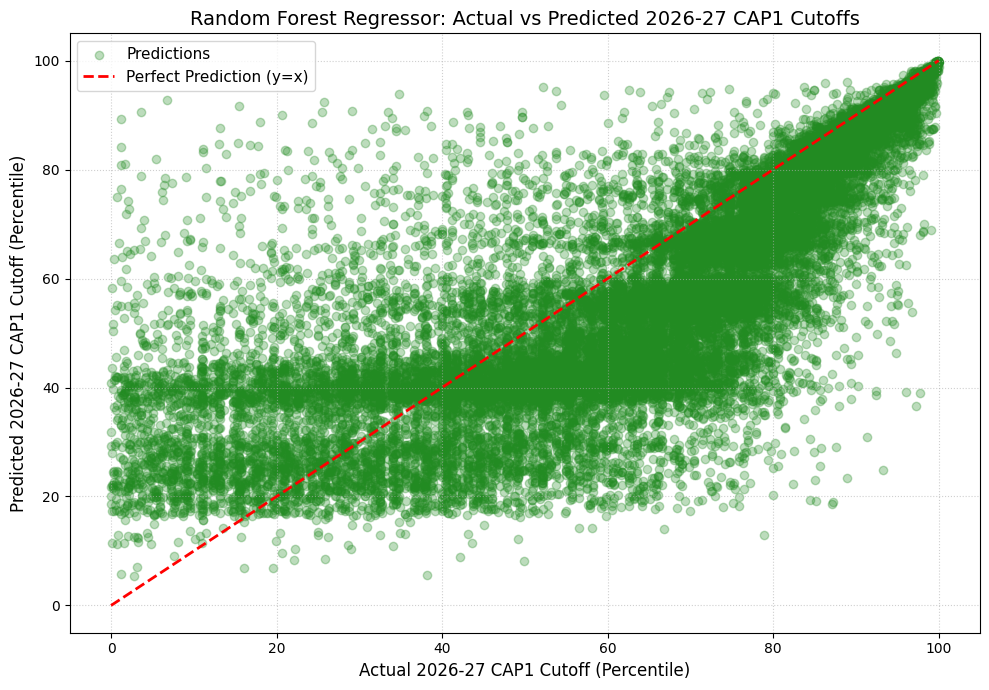

In [47]:
import matplotlib.pyplot as plt

# Ensure predicted cutoff column for Random Forest is available
rf_predictions = results["Random Forest"]["Predictions"]

# Create the visualization
plt.figure(figsize=(10, 7))
plt.scatter(y_test, rf_predictions, alpha=0.3, color='forestgreen', label='Predictions')
plt.plot([0, 100], [0, 100], color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y=x)')

plt.title("Random Forest Regressor: Actual vs Predicted 2026-27 CAP1 Cutoffs", fontsize=14)
plt.xlabel("Actual 2026-27 CAP1 Cutoff (Percentile)", fontsize=12)
plt.ylabel("Predicted 2026-27 CAP1 Cutoff (Percentile)", fontsize=12)
plt.xlim(-5, 105)
plt.ylim(-5, 105)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [48]:
import os

# Create structured DataFrame for Calibrated Blended Ensemble predictions (Best Model)
ens_comparison = test_df[
    [
        "previous_year",
        "previous_round",
        "target_year",
        "target_round",
        "college_code",
        "college_name",
        "branch_code",
        "branch_name",
        "category",
        "seat_section",
        "previous_cutoff",
        "actual_cutoff"
    ]
].copy()

# Attach calibrated ensemble predictions and errors
best_preds = results["Calibrated Blended Ensemble"]["Predictions"]
med_err = results["Calibrated Blended Ensemble"]["Median AE"]

ens_comparison["predicted_cutoff"] = np.round(best_preds, 4)
ens_comparison["predicted_cutoff_lower"] = np.clip(np.round(best_preds - med_err, 4), 0, 100)
ens_comparison["predicted_cutoff_upper"] = np.clip(np.round(best_preds + med_err, 4), 0, 100)
ens_comparison["absolute_error"] = np.round((ens_comparison["actual_cutoff"] - ens_comparison["predicted_cutoff"]).abs(), 4)
ens_comparison["smape"] = np.round((2 * ens_comparison["absolute_error"] / (ens_comparison["actual_cutoff"].abs() + ens_comparison["predicted_cutoff"].abs() + 1e-5)) * 100, 2)
ens_comparison["percentage_error"] = np.where(ens_comparison["actual_cutoff"] >= 10.0, np.round((ens_comparison["absolute_error"] / ens_comparison["actual_cutoff"]) * 100, 2), np.nan)

def error_category(e):
    if e <= 1: return "Very Close"
    if e <= 2: return "Close"
    if e <= 5: return "Reasonable"
    return "Large Difference"

ens_comparison["prediction_status"] = ens_comparison["absolute_error"].apply(error_category)

# Save both Random Forest and Calibrated Ensemble predictions
output_ensemble_file = "improved_ensemble_2026_CAP1_cutoff_predictions.csv"
ens_comparison.to_csv(output_ensemble_file, index=False)

# Also export Random Forest baseline
rf_comparison = ens_comparison.copy()
rf_comparison["predicted_cutoff"] = np.round(results["Random Forest"]["Predictions"], 4)
rf_comparison["absolute_error"] = np.round((rf_comparison["actual_cutoff"] - rf_comparison["predicted_cutoff"]).abs(), 4)
rf_comparison.to_csv("random_forest_2026_CAP1_cutoff_predictions.csv", index=False)

print(f"Calibrated Ensemble predictions successfully exported to: {output_ensemble_file}")
print(f"Shape of exported predictions: {ens_comparison.shape}")
display(ens_comparison.head(10))


Calibrated Ensemble predictions successfully exported to: improved_ensemble_2026_CAP1_cutoff_predictions.csv
Shape of exported predictions: (27836, 19)


,previous_year,previous_round,target_year,target_round,college_code,college_name,branch_code,branch_name,category,seat_section,previous_cutoff,actual_cutoff,predicted_cutoff,predicted_cutoff_lower,predicted_cutoff_upper,absolute_error,smape,percentage_error,prediction_status
4254,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOBCS,Minority,73.261286,40.416241,81.4395,75.5396,87.3393,41.0233,67.33,101.50,Large Difference
4255,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,DEFOPENS,Minority,85.850125,80.471614,79.1720,73.2721,85.0718,1.2996,1.63,1.61,Close
4256,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,EWS,Minority,71.475525,84.378631,73.0594,67.1596,78.9593,11.3192,14.38,13.41,Large Difference
4257,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT1S,Minority,85.191956,90.965732,92.4894,86.5895,98.3892,1.5237,1.66,1.68,Close
4258,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT2S,Minority,83.205858,88.245893,90.5716,84.6717,96.4714,2.3257,2.60,2.64,Reasonable
4259,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GNT3S,Minority,84.873660,90.814647,91.9120,86.0122,97.8119,1.0974,1.20,1.21,Close
4260,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOBCS,Minority,86.675175,90.570406,93.1445,87.2446,99.0444,2.5741,2.80,2.84,Reasonable
4261,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GOPENS,Minority,88.248475,91.785826,94.0223,88.1224,99.9222,2.2365,2.41,2.44,Reasonable
4262,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GSCS,Minority,82.553206,85.692151,90.0968,84.1970,95.9967,4.4046,5.01,5.14,Reasonable
4263,2025,CAP4,2026,CAP1,1002,"Government College of Engineering, Amravati",100219110,Civil Engineering,GSEBCS,Minority,77.161886,89.683008,86.0063,80.1064,91.9061,3.6767,4.19,4.10,Reasonable


In [49]:
# Inspect the columns of feature sets to verify there is no leakage of the target variable
print("Features included in X_train/X_test:", X_train.columns.tolist())

# Confirm that 'actual_cutoff' is not in X_train or X_test
target_in_train = 'actual_cutoff' in X_train.columns
target_in_test = 'actual_cutoff' in X_test.columns

print(f"Is 'actual_cutoff' present in X_train? {target_in_train}")
print(f"Is 'actual_cutoff' present in X_test? {target_in_test}")

# Let's inspect the first 5 rows of X_test to visually confirm the inputs
display(X_test.head())

Features included in X_train/X_test: ['college_code', 'branch_code', 'category', 'previous_cutoff', 'current_branch_intake', 'intake_change_absolute', 'is_expanded_branch', 'is_special_quota', 'is_female', 'college_avg_cutoff']
Is 'actual_cutoff' present in X_train? False
Is 'actual_cutoff' present in X_test? False


,college_code,branch_code,category,previous_cutoff,current_branch_intake,intake_change_absolute,is_expanded_branch,is_special_quota,is_female,college_avg_cutoff
4254,1002,100219110,DEFOBCS,73.261286,60.0,0.0,0,1,0,83.311487
4255,1002,100219110,DEFOPENS,85.850125,60.0,0.0,0,1,0,83.311487
4256,1002,100219110,EWS,71.475525,60.0,0.0,0,0,0,83.311487
4257,1002,100219110,GNT1S,85.191956,60.0,0.0,0,0,0,83.311487
4258,1002,100219110,GNT2S,83.205858,60.0,0.0,0,0,0,83.311487
